# 02 — The 2D pseudo-image CNN

The spec's headline comparator (§2): a 2D CNN over each person's `C x T` array with **4×5
kernels**, so that channel order is treated as spatial. It is the model the permutation
experiment (§6) is designed to break, and the one the proposed hierarchical TCN has to beat.

This notebook **trains nothing**. The job beside it
(`src/utils/data_analysis_02_pseudo_image_cnn_job.py`, driven by its `.sh`) runs nested
cross-validation shard by shard and writes Parquet; this notebook reads it.

| step | where | what |
|---|---|---|
| input | `shared_model_input` | `X`, mask, Delta, static covariates; standardised **per training fold** |
| model | `..._cnn_model` | causal-in-time 2D CNN → per-bin competing-risks head (disease, death) |
| tuning | `..._cnn_job` | 5 outer folds; 3 inner folds over the grid, by inner NLL — never reported |
| prediction | `shared_evaluation` | interval NLL, IPCW AUC and Brier at bins 10 and 20, C-index, decile calibration |
| recovery | `shared_evaluation` | Expected Gradients → map `A[c,t]` vs `w_true[c,t]` (spec §3.1–3.5) |
| sanity | `..._cnn_job` | Adebayo: weights re-drawn (every fold), labels shuffled (fold 0) |

**Status.** `doc/STATE.md` §3 still has the DGP review and the kill criteria open, and the spec
requires the kill criteria fixed *before any model runs*. Only the `smoke` profile has been run:
its numbers prove the plumbing and mean nothing else.

In [1]:
import sys
from pathlib import Path

# Anchor every path on the repo root regardless of where this is launched from.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "utils").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from utils import shared_paths as P

P.bootstrap()

%matplotlib inline

from datetime import date

import numpy as np
import pandas as pd
import torch

from utils.data_analysis_02_pseudo_image_cnn_figures import (
    attribution_figure,
    calibration_figure,
    calibration_rows,
    mean_maps,
    summary_table,
)
from utils.data_analysis_02_pseudo_image_cnn_job import load_profile, results_path, shard_dir
from utils.data_analysis_02_pseudo_image_cnn_model import PseudoImageCNN, resolve_device
from utils.shared_dgp import load_config
from utils.shared_model_input import OUTCOME_NAMES, load_model_input
from utils.shared_style import load_style

STYLE = load_style("02_pseudo_image_cnn")
FIGURE_DIR = P.PSEUDO_IMAGE_CNN_FIGURE_DIR
SAVE_DATE = date.today().strftime("%Y%m%d")

PROFILE = "smoke"  # "study" once the kill criteria are fixed and the job has run
config = load_profile(PROFILE)
cfg = load_config()
config["run"]

{'scenarios': ['critical_period'],
 'n': [2000],
 'replicates': 1,
 'outer_folds': 2,
 'inner_folds': 2,
 'horizons': [10, 20],
 'sanity_checks': True}

## The input

One dataset of the profile, as the model sees it. Three planes per person — standardised
values, the observation mask, and bins since last observation — plus the static covariates the
config names. **Frailty is withheld** (`static: [cohort, sex]`): no survey measures it. That
caps what any model here can reach: on `critical_period`, N = 10,000, the true hazards score
AUC 0.71 at bin 20 *with* frailty, while birth cohort and sex alone already give 0.60.

In [2]:
scenario, n = config["run"]["scenarios"][0], config["run"]["n"][0]
data = load_model_input(scenario, n)

print(f"{scenario}, N={data.n:,}: X {data.X.shape}, static used {config['static']}")
print(f"cells observed: {data.M.mean():.1%}")
counts = np.bincount(data.obs_type, minlength=3)
for name, count in zip(OUTCOME_NAMES, counts):
    print(f"  {name:<22} {count:>6,} ({count / data.n:.1%})")

critical_period, N=2,000: X (2000, 12, 20), static used ['cohort', 'sex']
cells observed: 54.6%
  event-free / censored   1,434 (71.7%)
  disease                   225 (11.2%)
  death                     341 (17.1%)


## The network

Causal in time: each convolution pads only on the left of the time axis, so the hazard for
bin *t* depends on bins ≤ *t* (`tests/test_model_pipeline.py` checks this). That matters
more than usual here — the DGP keeps channels observed after an event and the mask stops
recording attrition at the event, so a CNN that could look forward would read the outcome
off the image. The channel axis is padded symmetrically: a 4-tall kernel straddling two
streams *is* the 2D-image assumption under test.

In [3]:
arch = config["architecture"]
net = PseudoImageCNN(
    n_channels=cfg.C, n_bins=cfg.T, n_static=len(config["static"]),
    width=max(config["grid"]["width"]), depth=arch["depth"], kernel=tuple(arch["kernel"]),
    hidden=arch["hidden"], dropout=config["grid"]["dropout"][0], causal=arch["causal"],
)
receptive = arch["depth"] * (arch["kernel"][1] - 1) + 1
print(f"parameters (widest grid point): {sum(p.numel() for p in net.parameters()):,}")
print(f"time receptive field: {receptive} bins back, including the current one")
print(f"device: {resolve_device(config['device'])}  (torch {torch.__version__})")

parameters (widest grid point): 6,106
time receptive field: 9 bins back, including the current one
device: mps  (torch 2.14.1)


## Running it

Not from here. Size the study before running it — `probe` times one shard:

```bash
PROFILE=smoke src/utils/data_analysis_02_pseudo_image_cnn_job.sh local   # minutes; plumbing
PROFILE=study src/utils/data_analysis_02_pseudo_image_cnn_job.sh shards  # list the work
PROFILE=study src/utils/data_analysis_02_pseudo_image_cnn_job.sh probe   # time one shard
PROFILE=study SHARD=17 src/utils/data_analysis_02_pseudo_image_cnn_job.sh local  # one array task
PROFILE=study src/utils/data_analysis_02_pseudo_image_cnn_job.sh merge
```

A finished shard is skipped on re-run; `FORCE=1` re-runs it.

In [4]:
results = pd.read_parquet(results_path(PROFILE))
shards = sorted(shard_dir(PROFILE).glob("*.npz"))
print(f"{PROFILE}: {results[['scenario', 'n', 'replicate', 'fold']].drop_duplicates().shape[0]} fits, "
      f"{results['metric'].nunique()} metrics")

PREDICTION = ["interval_nll", "auc_disease_t10", "auc_disease_t20", "brier_disease_t20",
              "c_index_disease", "ici_decile"]
RECOVERY = ["spearman_cells", "spearman_stream_time", "window_auprc", "stream_share_tv",
            "peak_time_error_upstream", "flatness_cv",
            "sanity_param_random_similarity", "sanity_label_random_similarity"]
summary_table(results, PREDICTION + RECOVERY)

smoke: 2 fits, 26 metrics


median    q25    q75  \
scenario        n    metric                                                 
critical_period 2000 auc_disease_t10                  0.575  0.571  0.578   
                     auc_disease_t20                  0.579  0.574  0.584   
                     brier_disease_t20                0.119  0.118  0.119   
                     c_index_disease                  0.549  0.543  0.554   
                     flatness_cv                      0.869  0.834  0.905   
                     ici_decile                       0.020  0.019  0.020   
                     interval_nll                     0.119  0.119  0.120   
                     peak_time_error_upstream         4.500  3.750  5.250   
                     sanity_label_random_similarity   0.802  0.802  0.802   
                     sanity_param_random_similarity   0.683  0.671  0.696   
                     spearman_cells                   0.310  0.298  0.321   
                     spearman_stream_time             0.358  0.351  0.364   
                     stream_share_tv                  0.431  0.404  0.458   
                     window_auprc                     0.274  0.253  0.294   

                                                     fits  
scenario        n    metric                                
critical_period 2000 auc_disease_t10                    2  
                     auc_disease_t20                    2  
                     brier_disease_t20                  2  
                     c_index_disease                    2  
                     flatness_cv                        2  
                     ici_decile                         2  
                     interval_nll                       2  
                     peak_time_error_upstream           2  
                     sanity_label_random_similarity     1  
                     sanity_param_random_similarity     2  
                     spearman_cells                     2  
                     spearman_stream_time               2  
                     stream_share_tv                    2  
                     window_auprc                       2

## Attribution against truth

Expected Gradients on the predicted disease CIF at age 90, 50 training-set baselines, averaged
per cell over the test people who **observed** that cell. A plain average would print the
missingness pattern — midstream is unobserved in ~75% of person-bins — onto every map, trained
or random, and the Adebayo checks would then pass two copies of the mask as "similar".

Reading the panels: the trained map should look like the truth, and the two controls should
*not* look like the trained map. If the controls resemble it, the map is explaining the
architecture or the input, not what the model learnt.

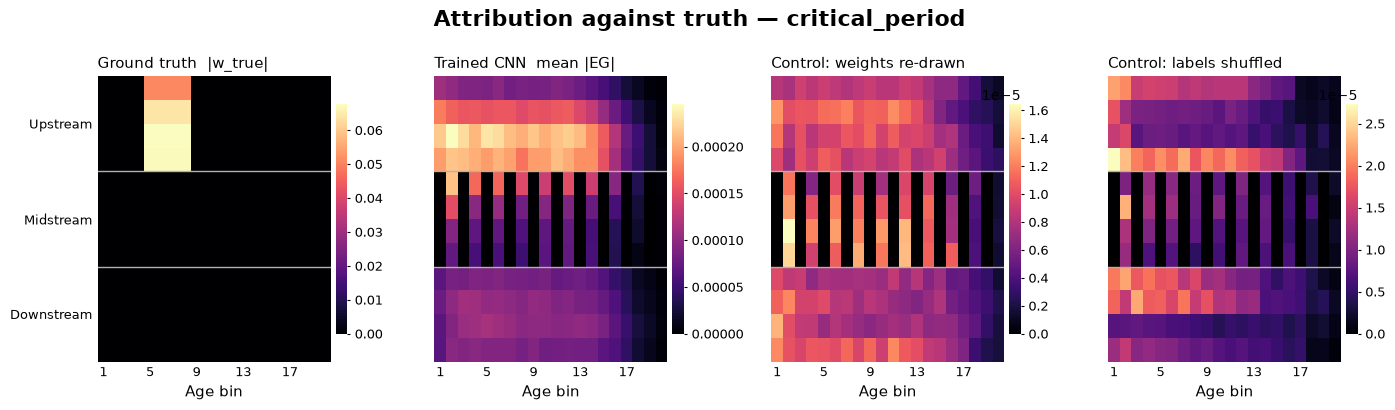

In [5]:
for scenario in config["run"]["scenarios"]:
    files = [f for f in shards if f.name.startswith(f"{scenario}_")]
    fig = attribution_figure(mean_maps(files), scenario, cfg.channels_per_stream, STYLE)
    fig.savefig(FIGURE_DIR / f"attribution_{PROFILE}_{scenario}_{SAVE_DATE}.pdf")
fig

## Calibration

One point per risk decile per fold. Spec §4 asks for calibration with the same prominence as
discrimination: a model that ranks well and calibrates badly is not a win.

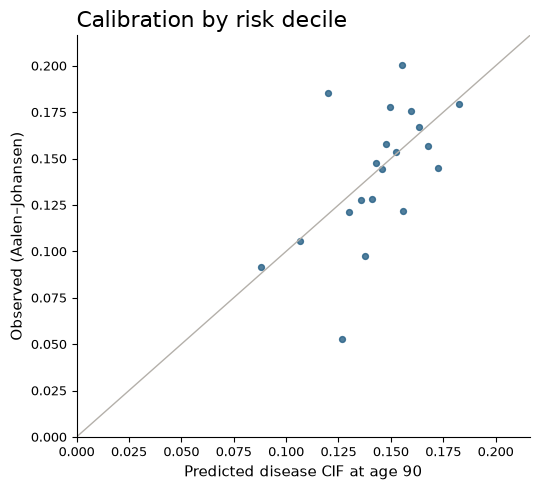

In [6]:
fig = calibration_figure(calibration_rows(shards), STYLE)
fig.savefig(FIGURE_DIR / f"calibration_{PROFILE}_{SAVE_DATE}.pdf")
fig

## What this cannot support yet

- **Any claim from the `smoke` profile.** Six epochs, one grid point, N = 2,000, two folds. The
  numbers above test that every stage connects, nothing more.
- **Any claim before the kill criteria are written down** (`doc/STATE.md` §3, spec §8).
- **The Antolini C-index.** `c_index_disease` is the Harrell-type competing-risks C (Wolbers),
  without censoring weights, and is labelled as such. `ici_decile` is a binned stand-in for the
  integrated calibration index.
- **Chain detection (spec §3.6)** and the **permutation experiment (§6)** are not built yet; both
  need a fitted model to perturb, and both belong in this job when they are.

What development showed, on one fold of `critical_period` at N = 10,000 with one hand-set
grid point (width 16, lr 0.001) — recorded so it is not rediscovered, not as a result:

| | value | for scale |
|---|---|---|
| AUC at bin 20 | 0.606 | cohort + sex alone 0.599; true hazards (with frailty) 0.710 |
| decile calibration error | 0.017 | true hazards 0.011 |
| recovery Spearman | 0.03 | |
| map similarity, weights re-drawn / labels shuffled | 0.90 / 0.81 | a map that explains the model should be low |

The CNN learnt little beyond cohort and sex, and its attribution map is close to both Adebayo
controls: all three carry the even/odd stripe of the midstream rotation. Whether nested tuning
changes that is what the study run is for. Two pipeline bugs were found on the way and fixed:
the per-bin baseline started at a one-in-three hazard (calibration error was 0.09), and the
weight-randomisation control re-drew that baseline too, which pinned its map to bin 1.